In [30]:
import os
import json
import hashlib
import random
import re
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

warnings.filterwarnings('ignore')

# ── CONFIGURE THESE FOR YOUR MACHINE ──────────────────────────────────────────
DATASET_ROOT = Path(r"C:\yolo\ppe\data")
EDA_OUT      = Path(r"C:\yolo\ppe\eda_output")
EDA_OUT.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test"]     # matches your folder names exactly

# Type-first layout: data/images/<split>, data/labels/<split>
def img_dir_for(split): return DATASET_ROOT / "images" / split
def lbl_dir_for(split): return DATASET_ROOT / "labels" / split

# Full class map. VERIFY against data.yaml (see check below) before trusting it.
ALL_CLASSES = {
    0: "helmet", 1: "gloves", 2: "vest",    3: "boots",
    4: "goggles", 5: "none",  6: "Person",  7: "no_helmet",
    8: "no_goggle", 9: "no_gloves", 10: "no_boots"
}

KEEP_CLASSES = {0, 1, 2, 3, 4, 6}
DROP_CLASSES = {5, 7, 8, 9, 10}
KEEP_CLASS_NAMES = {k: v for k, v in ALL_CLASSES.items() if k in KEEP_CLASSES}

# ── Sanity checks: fail loudly now instead of silently later ─────────────────
for s in SPLITS:
    assert img_dir_for(s).exists(), f"Missing {img_dir_for(s)}"
    assert lbl_dir_for(s).exists(), f"Missing {lbl_dir_for(s)}"

print("Setup complete.")
print(f"Dataset root : {DATASET_ROOT}")
print(f"Output dir   : {EDA_OUT}")
print(f"Keep classes : {KEEP_CLASS_NAMES}")
print(f"Drop classes : {[ALL_CLASSES[c] for c in sorted(DROP_CLASSES)]}")

Setup complete.
Dataset root : C:\yolo\ppe\data
Output dir   : C:\yolo\ppe\eda_output
Keep classes : {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 6: 'Person'}
Drop classes : ['none', 'no_helmet', 'no_goggle', 'no_gloves', 'no_boots']


In [31]:
# ── STEP 1: INTEGRITY AUDIT ───────────────────────────────────────────────────
# Checks: image/label pairing, parseable lines, valid class IDs,
# coords in [0,1], duplicate boxes, tiny boxes, empty label files.

TINY_AREA = 0.0004   # normalized area; = 2% x 2% of the image. One constant, reused in later steps.
VALID_IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def audit_split(split: str) -> dict:
    img_dir = img_dir_for(split)          # CHANGED: was IMAGE_DIR / split
    lbl_dir = lbl_dir_for(split)          # CHANGED: was LABEL_DIR / split

    images, dup_stems = {}, []
    for p in img_dir.iterdir():
        if p.suffix.lower() in VALID_IMG_EXTS:
            if p.stem in images:
                dup_stems.append(p.name)  # same stem, different extension
            images[p.stem] = p
    labels = {p.stem: p for p in lbl_dir.iterdir() if p.suffix.lower() == ".txt"}

    report = {
        "split": split,
        "image_count": len(images),
        "label_count": len(labels),
        "orphan_labels": [],       # structured list, so Step 6 doesn't parse error strings
        "images_no_label": [],
        "empty_labels": [],        # valid in YOLO (background images), but worth counting
        "errors": [],
        "warnings": [],
        "objects_raw": [],
        "objects_kept": [],
    }

    for name in dup_stems:
        report["errors"].append(f"Two images share a stem (different extension): {name}")

    for stem in labels:
        if stem not in images:
            report["orphan_labels"].append(stem)
            report["errors"].append(f"Orphaned label (no image): {labels[stem].name}")

    for stem in images:
        if stem not in labels:
            report["images_no_label"].append(stem)
            report["errors"].append(f"Image has no label: {images[stem].name}")

    for stem in images:
        if stem not in labels:
            continue
        lbl_path = labels[stem]
        with open(lbl_path, "r", encoding="utf-8") as f:
            raw_lines = [l.strip() for l in f if l.strip()]

        if not raw_lines:
            report["empty_labels"].append(stem)
            continue

        seen = set()
        for line_num, line in enumerate(raw_lines, start=1):
            parts = line.split()
            if len(parts) < 5:
                report["errors"].append(f"{lbl_path.name}:{line_num}: expected >=5 tokens, got {len(parts)}")
                continue
            if len(parts) > 5:
                report["warnings"].append(
                    f"{lbl_path.name}:{line_num}: {len(parts)} tokens (polygon/pose format?). "
                    f"Only the first 5 are used here.")
            try:
                cls = int(parts[0])
                x, y, w, h = map(float, parts[1:5])
            except ValueError:
                report["errors"].append(f"{lbl_path.name}:{line_num}: cannot parse numbers")
                continue

            if cls not in ALL_CLASSES:
                report["errors"].append(f"{lbl_path.name}:{line_num}: unknown class_id {cls}")
                continue
            if not (0.0 <= x <= 1.0 and 0.0 <= y <= 1.0 and 0.0 < w <= 1.0 and 0.0 < h <= 1.0):
                report["errors"].append(
                    f"{lbl_path.name}:{line_num}: coords out of [0,1]: x={x:.4f} y={y:.4f} w={w:.4f} h={h:.4f}")
                continue

            area = w * h
            if area < TINY_AREA:
                report["warnings"].append(
                    f"{lbl_path.name}:{line_num}: tiny box area={area:.6f} cls={ALL_CLASSES[cls]}")

            box_key = (cls, round(x, 4), round(y, 4), round(w, 4), round(h, 4))
            if box_key in seen:
                report["warnings"].append(
                    f"{lbl_path.name}:{line_num}: duplicate box {ALL_CLASSES[cls]} @ ({x:.3f},{y:.3f})")
                continue          # CHANGED: don't count the duplicate in class stats
            seen.add(box_key)

            record = {"cls": cls, "name": ALL_CLASSES[cls], "x": x, "y": y,
                      "w": w, "h": h, "area": area, "image": stem, "split": split}
            report["objects_raw"].append(record)
            if cls in KEEP_CLASSES:
                report["objects_kept"].append(record)

    return report


print("Running integrity audit...\n")
audit_results = {}
for split in SPLITS:
    r = audit_split(split)
    audit_results[split] = r
    print("=" * 50); print(f"  {split.upper()}"); print("=" * 50)
    print(f"  Images         : {r['image_count']}")
    print(f"  Labels         : {r['label_count']}")
    print(f"  Empty labels   : {len(r['empty_labels'])}")
    print(f"  Objects (raw)  : {len(r['objects_raw'])}")
    print(f"  Objects (kept) : {len(r['objects_kept'])}")
    print(f"  Errors         : {len(r['errors'])}")
    print(f"  Warnings       : {len(r['warnings'])}")
    for e in r["errors"][:5]:
        print(f"    ✗ {e}")
    if len(r["errors"]) > 5:
        print(f"    ... and {len(r['errors']) - 5} more")
    for wmsg in r["warnings"][:5]:
        print(f"    ⚠ {wmsg}")
    print()

Running integrity audit...

  TRAIN
  Images         : 1132
  Labels         : 1142
  Empty labels   : 0
  Objects (raw)  : 9097
  Objects (kept) : 7179
  Errors         : 10
  Warnings       : 18
    ✗ Orphaned label (no image): image940(1).txt
    ✗ Orphaned label (no image): image941(1).txt
    ✗ Orphaned label (no image): image944(1).txt
    ✗ Orphaned label (no image): image945(1).txt
    ✗ Orphaned label (no image): image946(1).txt
    ... and 5 more
    ⚠ image1156.txt:21: tiny box area=0.000325 cls=no_goggle
    ⚠ image1162.txt:43: tiny box area=0.000306 cls=no_goggle
    ⚠ image1368.txt:1: tiny box area=0.000348 cls=no_goggle
    ⚠ image1368.txt:19: tiny box area=0.000363 cls=no_goggle
    ⚠ image1387.txt:8: tiny box area=0.000379 cls=no_goggle

  VAL
  Images         : 143
  Labels         : 143
  Empty labels   : 0
  Objects (raw)  : 1172
  Objects (kept) : 945
  Errors         : 0
  Warnings       : 0

  TEST
  Images         : 141
  Labels         : 141
  Empty labels   : 

In [32]:
# ── CLASS IMBALANCE: instance collection ─────────────────────────────────────
# instances[split][class_id] -> list of (image_stem, line_no), one per instance

def collect_instances(split: str):
    per_class = {cid: [] for cid in ALL_CLASSES}
    bad_lines = []

    for lbl_path in sorted(lbl_dir_for(split).glob("*.txt")):
        with open(lbl_path, "r", encoding="utf-8") as f:
            for line_no, raw in enumerate(f, start=1):
                line = raw.strip()
                if not line:
                    continue
                parts = line.split()
                try:
                    cid = int(parts[0])
                except ValueError:
                    bad_lines.append((lbl_path.name, line_no, "non-integer class id"))
                    continue
                if cid not in per_class:
                    bad_lines.append((lbl_path.name, line_no, f"unknown class id {cid}"))
                    continue
                per_class[cid].append((lbl_path.stem, line_no))
    return per_class, bad_lines

instances, bad_lines = {}, {}
for split in SPLITS:
    instances[split], bad_lines[split] = collect_instances(split)

# ── Report ───────────────────────────────────────────────────────────────────
for split in SPLITS:
    inst = instances[split]
    kept_total = sum(len(inst[c]) for c in KEEP_CLASSES)

    print(f"\n── {split.upper()} ──  (malformed lines: {len(bad_lines[split])})")
    print(f"{'id':<3} {'class':<11} {'instances':>9} {'images':>7} {'% of kept':>10}  status")
    for cid in sorted(ALL_CLASSES):
        n = len(inst[cid])
        n_imgs = len({stem for stem, _ in inst[cid]})
        status = "kept" if cid in KEEP_CLASSES else "DROP"
        pct = f"{100*n/kept_total:.1f}%" if cid in KEEP_CLASSES and kept_total else "—"
        print(f"{cid:<3} {ALL_CLASSES[cid]:<11} {n:>9} {n_imgs:>7} {pct:>10}  {status}")

    kept_counts = {ALL_CLASSES[c]: len(inst[c]) for c in KEEP_CLASSES if inst[c]}
    if kept_counts:
        hi, lo = max(kept_counts, key=kept_counts.get), min(kept_counts, key=kept_counts.get)
        print(f"Imbalance (kept): {kept_counts[hi]/kept_counts[lo]:.1f}x  ({hi} vs {lo})")


── TRAIN ──  (malformed lines: 0)
id  class       instances  images  % of kept  status
0   helmet           1357     840      18.7%  kept
1   gloves           1162     571      16.0%  kept
2   vest             1283     837      17.6%  kept
3   boots            1251     538      17.2%  kept
4   goggles           427     393       5.9%  kept
5   none              654     349          —  DROP
6   Person           1790    1077      24.6%  kept
7   no_helmet         400     232          —  DROP
8   no_goggle         337     216          —  DROP
9   no_gloves         442     190          —  DROP
10  no_boots           88      28          —  DROP
Imbalance (kept): 4.2x  (Person vs goggles)

── VAL ──  (malformed lines: 0)
id  class       instances  images  % of kept  status
0   helmet            201     107      21.3%  kept
1   gloves            136      68      14.4%  kept
2   vest              171     109      18.1%  kept
3   boots             151      64      16.0%  kept
4   goggles      

In [33]:
# ── Report (instance counts only) ────────────────────────────────────────────
for split in SPLITS:
    inst = instances[split]
    kept_total = sum(len(inst[c]) for c in KEEP_CLASSES)

    print(f"\n── {split.upper()} ──  (malformed lines: {len(bad_lines[split])})")
    print(f"{'id':<3} {'class':<11} {'instances':>9} {'% of kept':>10}  status")
    for cid in sorted(ALL_CLASSES):
        n = len(inst[cid])
        status = "kept" if cid in KEEP_CLASSES else "DROP"
        pct = f"{100*n/kept_total:.1f}%" if cid in KEEP_CLASSES and kept_total else "—"
        print(f"{cid:<3} {ALL_CLASSES[cid]:<11} {n:>9} {pct:>10}  {status}")

    kept_counts = {ALL_CLASSES[c]: len(inst[c]) for c in KEEP_CLASSES if inst[c]}
    if kept_counts:
        hi, lo = max(kept_counts, key=kept_counts.get), min(kept_counts, key=kept_counts.get)
        print(f"Imbalance (kept): {kept_counts[hi]/kept_counts[lo]:.1f}x  ({hi} vs {lo})")


── TRAIN ──  (malformed lines: 0)
id  class       instances  % of kept  status
0   helmet           1357      18.7%  kept
1   gloves           1162      16.0%  kept
2   vest             1283      17.6%  kept
3   boots            1251      17.2%  kept
4   goggles           427       5.9%  kept
5   none              654          —  DROP
6   Person           1790      24.6%  kept
7   no_helmet         400          —  DROP
8   no_goggle         337          —  DROP
9   no_gloves         442          —  DROP
10  no_boots           88          —  DROP
Imbalance (kept): 4.2x  (Person vs goggles)

── VAL ──  (malformed lines: 0)
id  class       instances  % of kept  status
0   helmet            201      21.3%  kept
1   gloves            136      14.4%  kept
2   vest              171      18.1%  kept
3   boots             151      16.0%  kept
4   goggles            47       5.0%  kept
5   none               81          —  DROP
6   Person            239      25.3%  kept
7   no_helmet          4

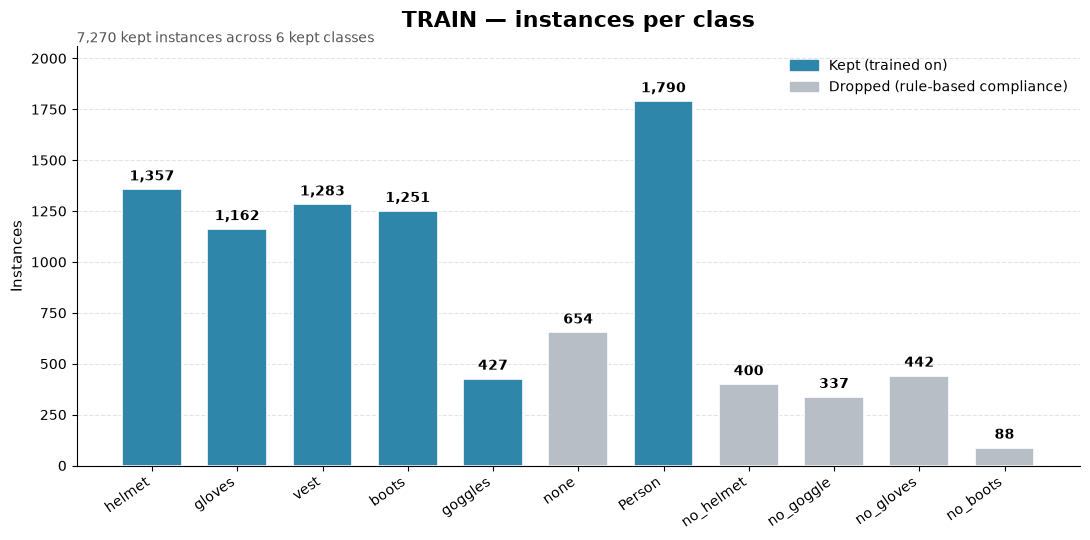

Saved → C:\yolo\ppe\eda_output\class_instances_train.png


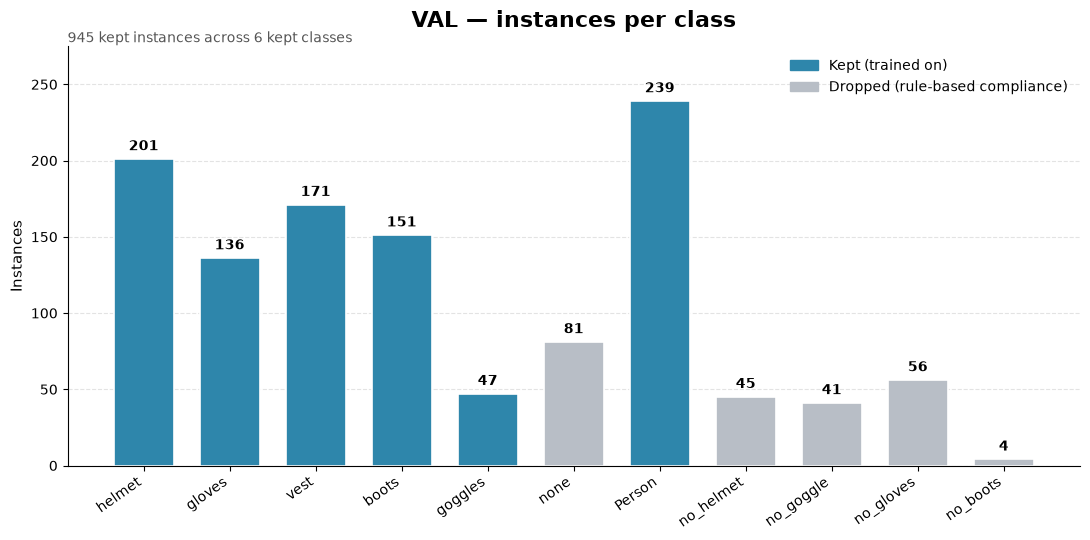

Saved → C:\yolo\ppe\eda_output\class_instances_val.png


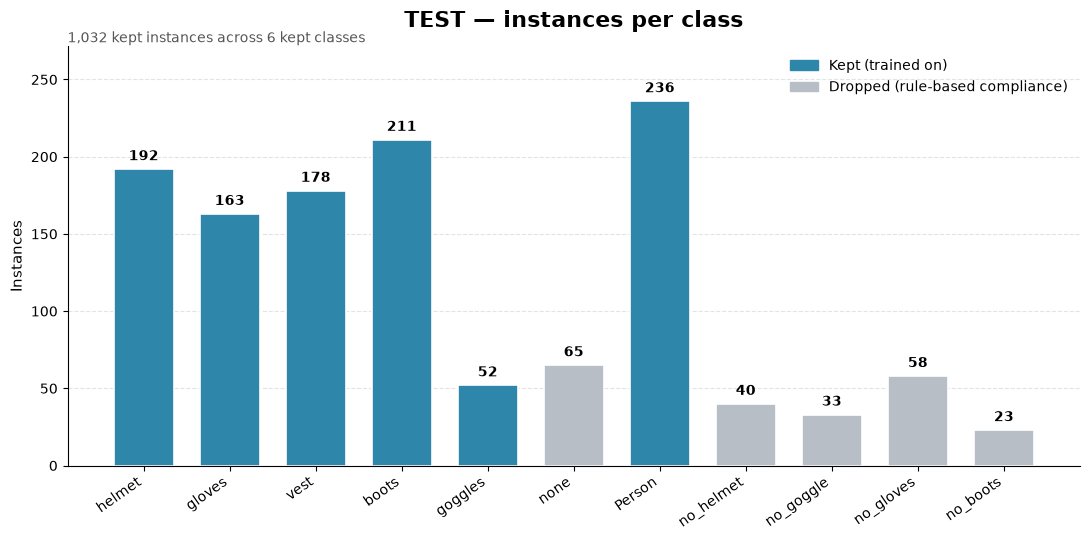

Saved → C:\yolo\ppe\eda_output\class_instances_test.png


In [34]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

KEPT_COLOR, DROP_COLOR = "#2E86AB", "#B8BEC6"

def plot_split(split: str, log_scale: bool = False):
    inst = instances[split]
    cids   = sorted(ALL_CLASSES)
    names  = [ALL_CLASSES[c] for c in cids]
    counts = [len(inst[c]) for c in cids]
    colors = [KEPT_COLOR if c in KEEP_CLASSES else DROP_COLOR for c in cids]

    fig, ax = plt.subplots(figsize=(11, 5.5))
    bars = ax.bar(names, counts, color=colors, edgecolor="white", linewidth=1.2, width=0.7)

    # value labels on top of each bar
    for bar, n in zip(bars, counts):
        ax.annotate(f"{n:,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    xytext=(0, 4), textcoords="offset points")

    if log_scale:
        ax.set_yscale("log")
    ax.set_ylim(top=max(counts) * (2.5 if log_scale else 1.15))

    kept_total = sum(len(inst[c]) for c in KEEP_CLASSES)
    ax.set_title(f"{split.upper()} — instances per class", fontsize=16, fontweight="bold", pad=14)
    ax.set_suptitle = None
    ax.text(0.0, 1.01, f"{kept_total:,} kept instances across {len(KEEP_CLASSES)} kept classes",
            transform=ax.transAxes, fontsize=10, color="#555")
    ax.set_ylabel("Instances" + (" (log scale)" if log_scale else ""), fontsize=11)
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=10)

    # clean look
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.yaxis.grid(True, linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    ax.legend(handles=[Patch(color=KEPT_COLOR, label="Kept (trained on)"),
                       Patch(color=DROP_COLOR, label="Dropped (rule-based compliance)")],
              frameon=False, loc="upper right")

    fig.tight_layout()
    out = EDA_OUT / f"class_instances_{split}.png"
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved → {out}")

for split in SPLITS:
    plot_split(split)

In [35]:
# ── STEP 3: BOX GEOMETRY ──────────────────────────────────────────────────────
# Standard stats: size, aspect ratio, position heatmaps.
# Your-architecture-specific: analyse PPE box sizes relative to Person box size.
#   → A helmet box that's 80% the size of the Person box is wrong.
#   → A helmet box < 1% of image is a calibration challenge.

def get_geometry_stats(objects: list) -> dict:
    """Compute per-class geometry statistics from object records."""
    stats = defaultdict(lambda: {"areas": [], "widths": [], "heights": [],
                                  "aspect_ratios": [], "cx": [], "cy": []})
    for obj in objects:
        name = obj["name"]
        stats[name]["areas"].append(obj["area"])
        stats[name]["widths"].append(obj["w"])
        stats[name]["heights"].append(obj["h"])
        stats[name]["aspect_ratios"].append(
            obj["w"] / obj["h"] if obj["h"] > 0 else 0
        )
        stats[name]["cx"].append(obj["x"])   # center x
        stats[name]["cy"].append(obj["y"])   # center y
    return stats


print("BOX GEOMETRY ANALYSIS (Kept classes)")
print("="*90)
print(f"{'Class':<10} {'N':>5} {'AvgArea':>9} {'AvgW':>7} {'AvgH':>7} "
      f"{'MedianAR':>9} {'Tiny(<0.5%)':>12} {'Note'}")
print("-"*90)

for split in SPLITS:
    r = audit_results[split]
    geo = get_geometry_stats(r["objects_kept"])

    print(f"\n── {split.upper()} ──")
    for cls_name in [ALL_CLASSES[c] for c in sorted(KEEP_CLASSES)]:
        d = geo.get(cls_name)
        if not d or not d["areas"]:
            print(f"  {cls_name:<10}  (no instances)")
            continue

        n        = len(d["areas"])
        avg_area = np.mean(d["areas"])
        avg_w    = np.mean(d["widths"])
        avg_h    = np.mean(d["heights"])
        med_ar   = np.median(d["aspect_ratios"])
        tiny     = sum(1 for a in d["areas"] if a < 0.005)

        # Note for your architecture
        note = ""
        if cls_name == "helmet" and avg_area < 0.005:
            note = "← small: keypoint distance thresholds need tight α"
        elif cls_name == "Person" and avg_area > 0.15:
            note = "← large person boxes: proximity fallback viable"
        elif cls_name in ["gloves", "boots"] and avg_area < 0.003:
            note = "← very small: expect low recall"

        print(f"  {cls_name:<10} {n:>5} {avg_area:>9.5f} {avg_w:>7.4f} {avg_h:>7.4f} "
              f"{med_ar:>9.3f} {tiny:>12}  {note}")

BOX GEOMETRY ANALYSIS (Kept classes)
Class          N   AvgArea    AvgW    AvgH  MedianAR  Tiny(<0.5%) Note
------------------------------------------------------------------------------------------

── TRAIN ──
  helmet      1341   0.01633  0.1369  0.1008     1.290          309  
  gloves      1146   0.00970  0.0891  0.0939     0.978          327  
  vest        1269   0.08289  0.2335  0.2995     0.784           43  
  boots       1235   0.01756  0.1222  0.1269     0.928          218  
  goggles      419   0.00787  0.1474  0.0505     3.039          125  
  Person      1769   0.25896  0.3581  0.6325     0.547            6  ← large person boxes: proximity fallback viable

── VAL ──
  helmet       201   0.01586  0.1332  0.1009     1.216           53  
  gloves       136   0.00811  0.0881  0.0878     1.045           38  
  vest         171   0.08629  0.2388  0.3027     0.765            3  
  boots        151   0.01887  0.1290  0.1298     0.975           23  
  goggles       47   0.00934  

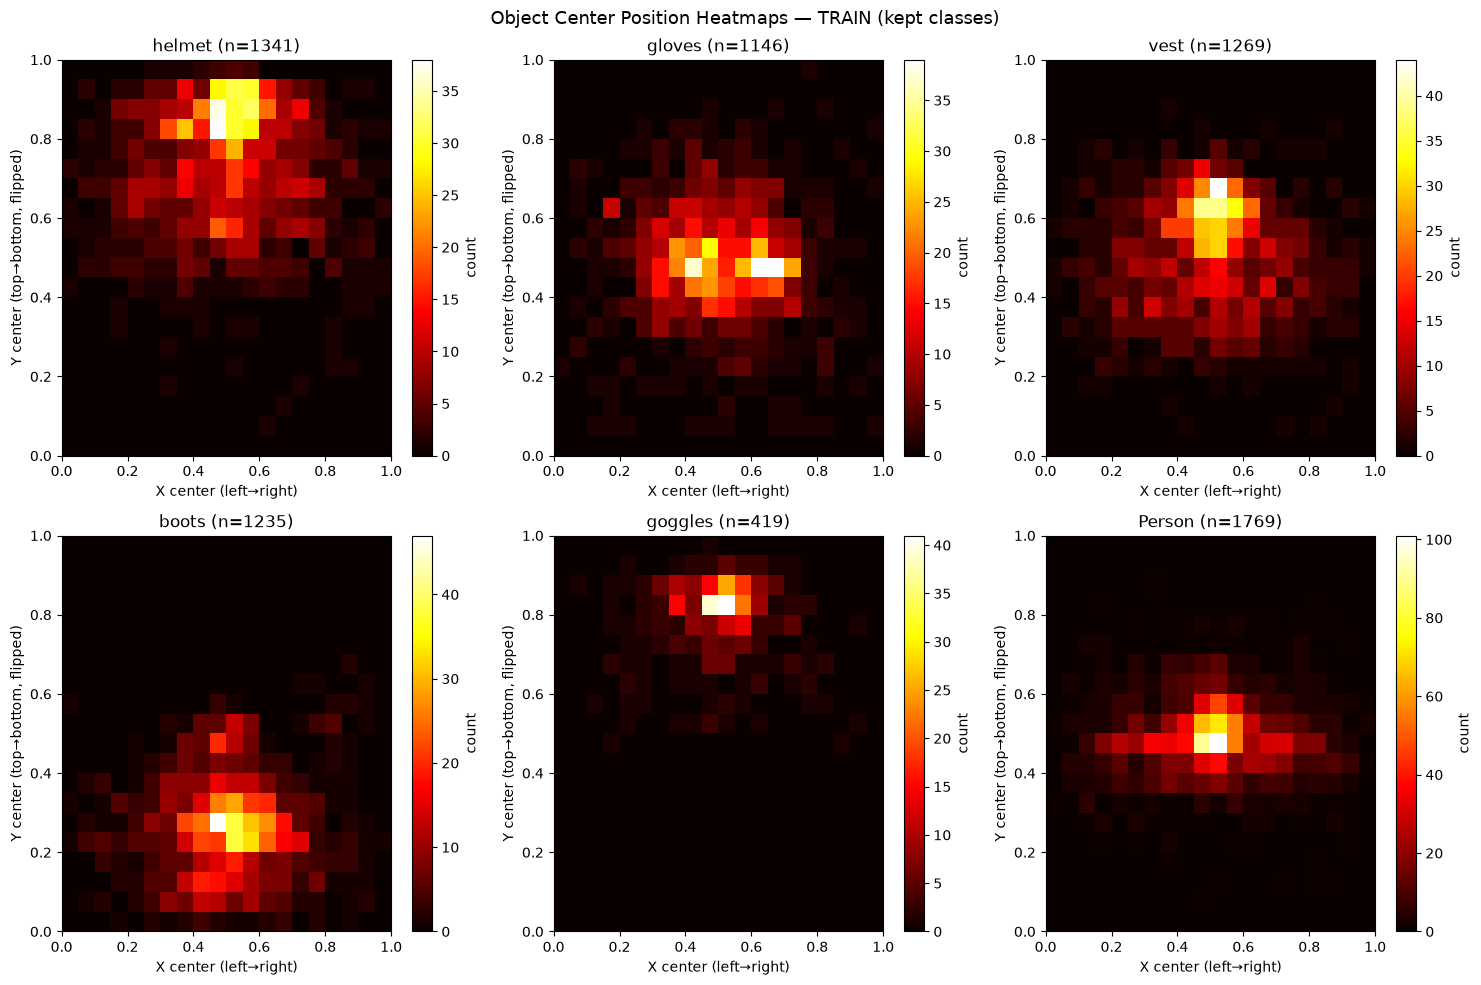

Saved → C:\yolo\ppe\eda_output\position_heatmaps.png


In [36]:
# Position heatmaps: where in the frame does each class tend to appear?
# Why: if helmets cluster in the top-third of the image,
#      that's consistent with real-world geometry (heads are at top).
#      If they're uniformly distributed, something's wrong.

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle(f"Object Center Position Heatmaps — TRAIN (kept classes)", fontsize=13)

kept_class_names = [ALL_CLASSES[c] for c in sorted(KEEP_CLASSES)]
geo_train = get_geometry_stats(audit_results["train"]["objects_kept"])

for idx, cls_name in enumerate(kept_class_names):
    ax = axes[idx // 3][idx % 3]
    d  = geo_train.get(cls_name, {})

    if not d or not d.get("cx"):
        ax.set_title(f"{cls_name} (no data)")
        continue

    cx = np.array(d["cx"])
    cy = np.array(d["cy"])

    # 2D histogram = heatmap
    h, xedges, yedges = np.histogram2d(cx, cy, bins=20,
                                        range=[[0,1],[0,1]])

    # y-axis: 0 = top of image in image coordinates,
    # but numpy plots 0 at bottom. Flip for correct orientation.
    im = ax.imshow(h.T[::-1], extent=[0,1,0,1],
                   origin='lower', cmap='hot', aspect='auto')

    ax.set_title(f"{cls_name} (n={len(cx)})")
    ax.set_xlabel("X center (left→right)")
    ax.set_ylabel("Y center (top→bottom, flipped)")
    plt.colorbar(im, ax=ax, label="count")

plt.tight_layout()
plt.savefig(EDA_OUT / "position_heatmaps.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {EDA_OUT/'position_heatmaps.png'}")

In [37]:
# ── STEP 4: PERSON-TO-PPE SIZE RATIO ─────────────────────────────────────────
# Your compliance rule: d < min(box_w, box_h) × α
# where box_w, box_h are the PPE bounding box dimensions.
#
# So you need to know: how big is a helmet box relative to the person box
# in the SAME image? If helmets are 5% of person box size on average,
# your α has a tight operating range. If they're 25%, you have more room.
#
# This analysis also catches mislabeled boxes:
# a "helmet" box that's 90% the size of the person box is probably
# annotating the entire upper body, not just the helmet.

# Build a per-image record: {image_stem: {cls_name: [boxes]}}
def build_image_index(objects: list) -> dict:
    """Group objects by image stem."""
    index = defaultdict(lambda: defaultdict(list))
    for obj in objects:
        index[obj["image"]][obj["name"]].append(obj)
    return index


print("PERSON-TO-PPE SIZE RATIO ANALYSIS\n")
print("Why: your α threshold is applied to PPE box dimensions.")
print("This tells you whether that scale is consistent across the dataset.\n")

ppe_classes = ["helmet", "gloves", "vest", "boots", "goggles"]

for split in SPLITS:
    r = audit_results[split]
    img_index = build_image_index(r["objects_kept"])

    ratios = defaultdict(list)   # ppe_name → list of (ppe_area / person_area)

    for img_stem, class_boxes in img_index.items():
        person_boxes = class_boxes.get("Person", [])
        if not person_boxes:
            continue

        # Use the largest Person box in the image as reference
        ref_person = max(person_boxes, key=lambda b: b["area"])
        person_area = ref_person["area"]

        for ppe_name in ppe_classes:
            for ppe_box in class_boxes.get(ppe_name, []):
                ratio = ppe_box["area"] / person_area if person_area > 0 else None
                if ratio is not None and ratio < 2.0:  # ratio > 2 is a labeling error
                    ratios[ppe_name].append(ratio)

    print(f"── {split.upper()} ──")
    print(f"  {'PPE':<10} {'N':>5} {'Mean ratio':>11} {'Median':>8} "
          f"{'Min':>7} {'Max':>7}  {'Interpretation'}")
    print(f"  {'-'*80}")

    for ppe_name in ppe_classes:
        rs = ratios.get(ppe_name, [])
        if not rs:
            print(f"  {ppe_name:<10}  {'—':>5}")
            continue

        mean_r   = np.mean(rs)
        median_r = np.median(rs)
        min_r    = np.min(rs)
        max_r    = np.max(rs)

        # Interpret for your architecture
        if mean_r < 0.02:
            note = "very small → tight α, keypoint precision critical"
        elif mean_r < 0.08:
            note = "small → α = 0.3–0.5 likely, calibrate carefully"
        elif mean_r > 0.3:
            note = "large → check for over-annotated boxes"
        else:
            note = "reasonable scale for keypoint matching"

        # Flag suspiciously large ratios (possible annotation errors)
        huge = sum(1 for x in rs if x > 0.5)
        if huge > 0:
            note += f" | ⚠ {huge} boxes >50% person size (check labels)"

        print(f"  {ppe_name:<10} {len(rs):>5} {mean_r:>11.4f} {median_r:>8.4f} "
              f"{min_r:>7.4f} {max_r:>7.4f}  {note}")
    print()

PERSON-TO-PPE SIZE RATIO ANALYSIS

Why: your α threshold is applied to PPE box dimensions.
This tells you whether that scale is consistent across the dataset.

── TRAIN ──
  PPE            N  Mean ratio   Median     Min     Max  Interpretation
  --------------------------------------------------------------------------------
  helmet      1255      0.0597   0.0503  0.0015  0.3234  small → α = 0.3–0.5 likely, calibrate carefully
  gloves      1109      0.0266   0.0222  0.0047  0.2644  small → α = 0.3–0.5 likely, calibrate carefully
  vest        1188      0.2780   0.2522  0.0013  1.2566  reasonable scale for keypoint matching | ⚠ 94 boxes >50% person size (check labels)
  boots       1201      0.0570   0.0563  0.0034  0.3839  small → α = 0.3–0.5 likely, calibrate carefully
  goggles      414      0.0220   0.0203  0.0039  0.1124  small → α = 0.3–0.5 likely, calibrate carefully

── VAL ──
  PPE            N  Mean ratio   Median     Min     Max  Interpretation
  ---------------------------

In [38]:
# ── STEP 5: HARD NEGATIVE AUDIT ──────────────────────────────────────────────
# Your architecture doc says:
#   "Public dataset is almost all worn gear."
#   "Add hard negatives: helmets on hooks, in hands, on benches."
#
# This step quantifies the problem before you go looking for extra data.
# The dataset has no "helmet on hook" class — so we infer indirectly:
#
# Proxy: images where helmet appears WITHOUT a Person box nearby.
#   → If a helmet box exists but no Person box in that image,
#     the helmet is probably not being worn.
#   → This is not perfect, but it's the best we can do without
#     dedicated hard-negative labels.

print("HARD NEGATIVE PROXY ANALYSIS")
print("="*60)
print("Proxy: PPE instances in images with no Person box in the same image.\n")

for split in SPLITS:
    r = audit_results[split]
    img_index = build_image_index(r["objects_kept"])

    print(f"── {split.upper()} ──")

    for ppe_name in ppe_classes:
        ppe_without_person = 0
        ppe_total          = 0

        for img_stem, class_boxes in img_index.items():
            ppe_boxes    = class_boxes.get(ppe_name, [])
            person_boxes = class_boxes.get("Person", [])

            ppe_total += len(ppe_boxes)
            if ppe_boxes and not person_boxes:
                ppe_without_person += len(ppe_boxes)

        pct = 100 * ppe_without_person / ppe_total if ppe_total > 0 else 0
        flag = " ← potential hard negatives" if pct > 5 else ""
        print(f"  {ppe_name:<10}: {ppe_without_person:>4}/{ppe_total:<6} "
              f"({pct:5.1f}%) without Person{flag}")
    print()

print("Interpretation:")
print("  High % → dataset may already have some non-worn instances")
print("  ~0%    → dataset is all worn gear → you NEED to source hard negatives")
print("           (helmets on hooks/carried will be detected as 'worn' by the")
print("            keypoint rule because there IS a helmet box and the system")
print("            will try to associate it with the nearest person)")

HARD NEGATIVE PROXY ANALYSIS
Proxy: PPE instances in images with no Person box in the same image.

── TRAIN ──
  helmet    :   86/1341   (  6.4%) without Person ← potential hard negatives
  gloves    :   37/1146   (  3.2%) without Person
  vest      :   81/1269   (  6.4%) without Person ← potential hard negatives
  boots     :   34/1235   (  2.8%) without Person
  goggles   :    5/419    (  1.2%) without Person

── VAL ──
  helmet    :    6/201    (  3.0%) without Person
  gloves    :    0/136    (  0.0%) without Person
  vest      :    8/171    (  4.7%) without Person
  boots     :    2/151    (  1.3%) without Person
  goggles   :    0/47     (  0.0%) without Person

── TEST ──
  helmet    :   11/192    (  5.7%) without Person ← potential hard negatives
  gloves    :    5/163    (  3.1%) without Person
  vest      :   11/178    (  6.2%) without Person ← potential hard negatives
  boots     :    4/211    (  1.9%) without Person
  goggles   :    1/52     (  1.9%) without Person

Interpr